
# Classification Part B: Accident Severity Prediction

## 1. Introduction

Road traffic accidents are a major public safety concern. Predicting
the severity of an accident using the available accident-related
information can help identify patterns associated with different
severity levels.

In this project, machine learning classification algorithms are used
to predict accident severity using the Road Traffic Accident dataset.

## 2. Objectives

- Load and explore the accident severity dataset.
- Understand the target classes and the distribution of records.
- Preprocess categorical and numerical features.
- Train five classification algorithms required for Part B.
- Evaluate the models using multiple classification metrics.
- Tune a selected model to improve its performance.
- Compare Part A and Part B models using a consolidated results table.

## 3. Classification Algorithms

The five algorithms used in Part B are:

1. Random Forest Classifier
2. AdaBoost Classifier
3. Gradient Boosting Classifier
4. Bagging Classifier with a Decision Tree base estimator
5. Multi-Layer Perceptron Neural Network (MLP)

The final model will be selected based on its measured performance
and its ability to classify the accident severity categories.



## 4. Importing Libraries

This section imports the Python libraries required for data analysis,
visualization, preprocessing, model training, and evaluation.

- **Pandas:** Loads and manipulates tabular data.
- **NumPy:** Performs numerical operations.
- **Matplotlib and Seaborn:** Create visualizations.
- **Scikit-learn:** Provides preprocessing methods, classification
  algorithms, hyperparameter tuning, cross-validation, and evaluation
  metrics.

Importing all required libraries at the beginning makes the notebook
easier to organize and reproduce.


In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    BaggingClassifier
)

from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.base import clone

RANDOM_STATE = 42

print("All libraries imported successfully.")

All libraries imported successfully.



## 5. Dataset Loading

The dataset contains information about road traffic accidents.
Each row represents an accident record, and the columns contain
information describing the accident and its circumstances.

The dataset is loaded from a CSV file using Pandas. The first few
rows are displayed to verify that the file has been read correctly.

The number of rows and columns is also checked to understand the
size of the dataset before further analysis.


In [44]:
dataset_path =  r"C:\Users\saich\OneDrive\Desktop\ML\ML_Project\data\RTA Dataset.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)



Dataset loaded successfully.
Dataset shape: (12316, 32)


In [45]:
display(df.head())

,Time,Day_of_week,Age_band_of_driver,Sex_of_driver,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,...,Vehicle_movement,Casualty_class,Sex_of_casualty,Age_band_of_casualty,Casualty_severity,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,...,Going straight,Driver or rider,Male,31-50,3,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,...,Going straight,Pedestrian,Female,18-30,3,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,...,Going straight,na,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury



## 6. Dataset Structure and Data Types

Before training a machine learning model, it is necessary to
understand the dataset's structure.

The column names identify the available features. The data types
show which columns are numerical and which are categorical.
The information summary also helps identify columns containing
missing values.

This inspection is important because categorical and numerical
features generally require different preprocessing methods.


In [46]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['Time', 'Day_of_week', 'Age_band_of_driver', 'Sex_of_driver', 'Educational_level', 'Vehicle_driver_relation', 'Driving_experience', 'Type_of_vehicle', 'Owner_of_vehicle', 'Service_year_of_vehicle', 'Defect_of_vehicle', 'Area_accident_occured', 'Lanes_or_Medians', 'Road_allignment', 'Types_of_Junction', 'Road_surface_type', 'Road_surface_conditions', 'Light_conditions', 'Weather_conditions', 'Type_of_collision', 'Number_of_vehicles_involved', 'Number_of_casualties', 'Vehicle_movement', 'Casualty_class', 'Sex_of_casualty', 'Age_band_of_casualty', 'Casualty_severity', 'Work_of_casuality', 'Fitness_of_casuality', 'Pedestrian_movement', 'Cause_of_accident', 'Accident_severity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12316 entries, 0 to 12315
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         12316 non-null  object
 


## 7. Data Quality Assessment

Real-world datasets may contain missing values and duplicate
records. Missing values can cause problems during model training
if they are not handled appropriately.

This section counts the missing values in each column and checks
how many duplicate rows exist.

Missing values will later be handled using imputation inside the
preprocessing pipeline. This allows imputation values to be learned
from the training data rather than from the entire dataset.


In [47]:
missing_summary = df.isnull().sum().sort_values(ascending=False)

print("Columns with the most missing values:")
display(missing_summary.head(20))

print("Total duplicate rows:", df.duplicated().sum())

Columns with the most missing values:


Defect_of_vehicle          4427
Service_year_of_vehicle    3928
Work_of_casuality          3198
Fitness_of_casuality       2635
Type_of_vehicle             950
Types_of_Junction           887
Driving_experience          829
Educational_level           741
Vehicle_driver_relation     579
Owner_of_vehicle            482
Lanes_or_Medians            385
Vehicle_movement            308
Area_accident_occured       239
Road_surface_type           172
Type_of_collision           155
Road_allignment             142
Sex_of_driver                 0
Age_band_of_driver            0
Day_of_week                   0
Time                          0
dtype: int64

Total duplicate rows: 0



## 8. Target Variable Identification

The target variable is the value that the classification model
attempts to predict.

For this project, the expected target column is
`Accident_severity`. It contains the accident severity category
associated with each record.

The target distribution is examined to determine how many records
belong to each class. This is important because a dataset with
unequal class frequencies may cause a model to favor the majority
class.

The target column must be confirmed against the actual dataset
column names before continuing.


In [48]:
target_column = "Accident_severity"

if target_column not in df.columns:
    raise ValueError(
        f"Target column not found. Available columns: {df.columns.tolist()}"
    )

print("Target class counts:")
display(df[target_column].value_counts(dropna=False))

print("\nTarget class percentages:")
display(
    (df[target_column].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

Target class counts:


Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64


Target class percentages:


Accident_severity
Slight Injury     84.56
Serious Injury    14.15
Fatal injury       1.28
Name: proportion, dtype: float64


## 9. Target Class Distribution

A bar chart is used to visualize the number of records belonging
to each accident severity category.

This visualization makes class imbalance easier to identify.
If one category has many more records than another, accuracy alone
may not adequately describe model performance.

For that reason, weighted precision, weighted recall, weighted
F1-score, and multiclass ROC-AUC will also be considered during
model evaluation.


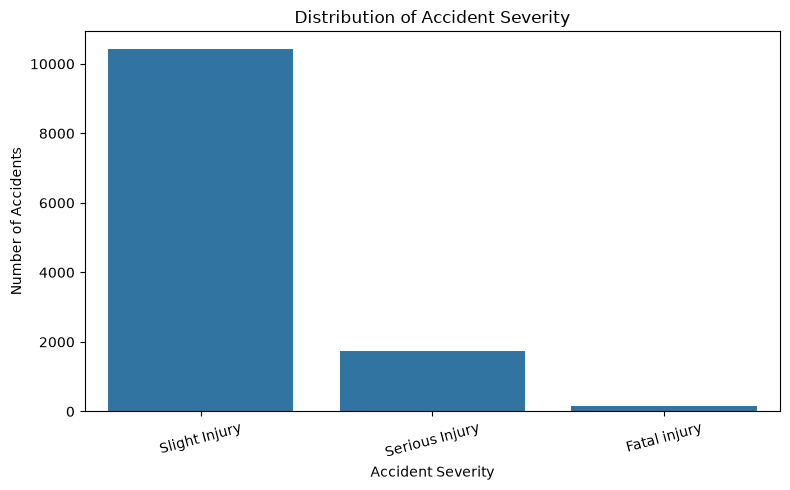

In [49]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x=target_column,
    order=df[target_column].value_counts().index
)

plt.title("Distribution of Accident Severity")
plt.xlabel("Accident Severity")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 10. Feature and Target Separation

The input features and target variable are separated before model
training.

- **Features (X):** The accident-related columns used to make a
  prediction.
- **Target (y):** The accident severity category to be predicted.

Rows with a missing target value cannot be used for supervised
classification and are removed.

The target column is excluded from the feature matrix to prevent
the model from receiving the answer it is supposed to predict.
Any other columns that directly reveal the target or would not be
available at prediction time should also be reviewed for leakage.


In [50]:
df = df.dropna(subset=[target_column]).copy()

X = df.drop(columns=[target_column])
y = df[target_column]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget classes:")
display(y.value_counts())

Feature matrix shape: (12316, 31)
Target vector shape: (12316,)

Target classes:


Accident_severity
Slight Injury     10415
Serious Injury     1743
Fatal injury        158
Name: count, dtype: int64


## 11. Train-Test Split

The dataset is divided into training and testing subsets.

The training set is used to learn patterns from the data. The
testing set is kept separate and is used to evaluate how well the
trained models generalize to unseen records.

An 80:20 split is used, with 80% of the records allocated to
training and 20% to testing.

Stratification preserves approximately the same target-class
proportions in both subsets. A fixed random state makes the split
reproducible.

All five Part B algorithms will use this same split.


In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).round(3))

Training features: (9852, 31)
Testing features: (2464, 31)

Training target distribution:


Accident_severity
Slight Injury     0.846
Serious Injury    0.141
Fatal injury      0.013
Name: proportion, dtype: float64


Testing target distribution:


Accident_severity
Slight Injury     0.846
Serious Injury    0.142
Fatal injury      0.013
Name: proportion, dtype: float64


## 12. Data Preprocessing

Machine learning algorithms require the input data to be represented
in a suitable numerical format.

The preprocessing pipeline treats numerical and categorical columns
differently.

### Numerical features

Missing numerical values are replaced with the median. Numerical
features are then standardized using `StandardScaler`. Scaling is
especially useful for the MLP neural network because it is sensitive
to differences in feature magnitudes.

### Categorical features

Missing categorical values are replaced with the most frequent
category. One-hot encoding converts categories into numerical
indicator features that can be used by the classifiers.

### Preventing data leakage

The preprocessing transformations are fitted using the training
features only. The fitted transformations are then applied to the
testing features. This prevents information from the test set from
influencing the preprocessing parameters.


In [52]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Numerical features: 2
Categorical features: 29
Processed training shape: (9852, 1249)
Processed testing shape: (2464, 1249)



## 13. Part B Classification Models

Five classification algorithms are selected for the second part
of the classification track.

1. **Random Forest:** Combines predictions from multiple decision
   trees. It can learn complex relationships and offers a
   `class_weight` option to help address class imbalance.

2. **AdaBoost:** Builds a sequence of weak learners, giving more
   attention to records that previous learners classified
   incorrectly.

3. **Gradient Boosting:** Builds trees sequentially, with each
   stage attempting to improve the errors of the existing model.

4. **Bagging with Decision Tree:** Trains multiple decision trees
   on resampled training data and combines their predictions.
   This can reduce the instability of an individual decision tree.

5. **MLP Neural Network:** Learns nonlinear relationships through
   interconnected layers of artificial neurons. Feature scaling
   is important for this algorithm.

All five models use the same processed training data and random
state where the algorithm supports it.


In [53]:
part_b_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "AdaBoost": AdaBoostClassifier(
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "Bagging (Decision Tree)": BaggingClassifier(
        estimator=DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        ),
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(100, 50),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        random_state=RANDOM_STATE
    )
}

print("Five Classification Models Defined.")

Five Classification Models Defined.



## 14. Model Training

Each classifier is fitted using the processed training data and
the training target labels.

The `fit()` method enables the algorithm to learn the relationship
between the input features and accident severity.

The fitted models are stored in a dictionary so that they can be
reused consistently for prediction, evaluation, and comparison.

Training results alone do not establish which algorithm is best.
Each model must also be evaluated on the held-out test data.


In [56]:

part_b_fitted_models = {}
part_b_predictions = {}

for model_name, model in part_b_models.items():
    print(f"\nTraining {model_name}...")

    try:
        # Disable MLP early stopping to avoid the validation-score error
        if model_name == "MLP Neural Network":
            model.set_params(early_stopping=False)

        model.fit(X_train_processed, y_train)

        part_b_fitted_models[model_name] = model
        part_b_predictions[model_name] = model.predict(X_test_processed)

        print(f"{model_name} trained successfully.")

    except Exception as e:
        print(f"Error while training {model_name}: {e}")
        raise

print("\nAll five Part B models trained successfully.")



Training Random Forest...
Random Forest trained successfully.

Training AdaBoost...
AdaBoost trained successfully.

Training Gradient Boosting...
Gradient Boosting trained successfully.

Training Bagging (Decision Tree)...
Bagging (Decision Tree) trained successfully.

Training MLP Neural Network...
MLP Neural Network trained successfully.

All five Part B models trained successfully.



## 15. Evaluation Metrics

The five models are evaluated on the same test set using the
following metrics.

- **Accuracy:** The proportion of all predictions that are correct.
- **Weighted Precision:** The precision of each class, averaged
  according to the number of true records in that class.
- **Weighted Recall:** The recall of each class, averaged according
  to class support.
- **Weighted F1-score:** A weighted average of class-level F1-scores,
  balancing precision and recall.
- **Multiclass ROC-AUC (OvR):** Measures the ability to distinguish
  each class from the remaining classes using a one-vs-rest approach.

Weighted metrics account for class frequencies, but they may still
hide weak performance on rare classes. Class-wise reports and
confusion matrices are therefore examined separately.


In [57]:
def calculate_metrics(model, X_eval, y_true, y_pred):
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Weighted": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall_Weighted": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    try:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_eval)
            results["ROC_AUC_OVR"] = roc_auc_score(
                y_true,
                y_score,
                labels=model.classes_,
                multi_class="ovr",
                average="weighted"
            )
        else:
            results["ROC_AUC_OVR"] = np.nan

    except (ValueError, AttributeError):
        results["ROC_AUC_OVR"] = np.nan

    return results


part_b_results = []

for model_name, model in part_b_fitted_models.items():
    metrics = calculate_metrics(
        model,
        X_test_processed,
        y_test,
        part_b_predictions[model_name]
    )

    metrics["Algorithm"] = model_name
    part_b_results.append(metrics)

part_b_results_df = pd.DataFrame(part_b_results)

display(
    part_b_results_df.sort_values(
        "F1_Weighted", ascending=False
    ).round(4)
)

,Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,ROC_AUC_OVR,Algorithm
4,0.8442,0.8216,0.8442,0.8291,0.7521,MLP Neural Network
3,0.8584,0.8398,0.8584,0.8167,0.7785,Bagging (Decision Tree)
2,0.8535,0.8289,0.8535,0.7997,0.6844,Gradient Boosting
0,0.8458,0.7153,0.8458,0.7751,0.6664,Random Forest
1,0.8458,0.7153,0.8458,0.7751,0.6082,AdaBoost



### 16.1 Classification Report — Random Forest

The Random Forest classifier combines predictions from multiple
decision trees to classify accident severity.

The classification report evaluates the model separately for each
severity class using precision, recall, and F1-score.

- Precision measures how many predictions for a class were correct.
- Recall measures how many actual records of a class were identified.
- F1-score balances precision and recall.
- Support indicates the number of actual test records in each class.

This report helps determine whether Random Forest performs well
across all accident severity categories, including minority classes.


In [58]:
print("RANDOM FOREST — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    part_b_predictions["Random Forest"],
    zero_division=0
))

RANDOM FOREST — CLASSIFICATION REPORT
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        31
Serious Injury       0.00      0.00      0.00       349
 Slight Injury       0.85      1.00      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.28      0.33      0.31      2464
  weighted avg       0.72      0.85      0.78      2464




### 16.2 Classification Report — AdaBoost

AdaBoost is an ensemble learning algorithm that combines multiple
weak learners into a stronger classifier. During training, it gives
greater attention to records that previous learners classified
incorrectly.

The classification report measures how effectively AdaBoost
predicts each accident severity category using precision, recall,
F1-score, and support.

The results can be compared with Random Forest to identify
differences in class-level prediction performance.


In [59]:
print("ADABOOST — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    part_b_predictions["AdaBoost"],
    zero_division=0
))

ADABOOST — CLASSIFICATION REPORT
                precision    recall  f1-score   support

  Fatal injury       0.00      0.00      0.00        31
Serious Injury       0.00      0.00      0.00       349
 Slight Injury       0.85      1.00      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.28      0.33      0.31      2464
  weighted avg       0.72      0.85      0.78      2464




### 16.3 Classification Report — Gradient Boosting

Gradient Boosting builds an ensemble of decision trees sequentially.
Each new tree attempts to improve the predictions of the existing
ensemble by learning from its errors.

The classification report evaluates its precision, recall,
F1-score, and support for every accident severity category.

Particular attention should be given to recall for minority classes,
because a model may achieve reasonable overall performance while
missing a substantial number of serious or fatal injury cases.


In [60]:
print("GRADIENT BOOSTING — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    part_b_predictions["Gradient Boosting"],
    zero_division=0
))

GRADIENT BOOSTING — CLASSIFICATION REPORT
                precision    recall  f1-score   support

  Fatal injury       0.62      0.32      0.43        31
Serious Injury       0.68      0.06      0.11       349
 Slight Injury       0.86      0.99      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.72      0.46      0.49      2464
  weighted avg       0.83      0.85      0.80      2464




### 16.4 Classification Report — Bagging with Decision Tree

Bagging trains multiple decision tree classifiers using different
bootstrap samples of the training data and combines their predictions.

This ensemble approach can reduce the variability of a single
decision tree and improve the stability of predictions.

The classification report shows how well the Bagging classifier
recognizes each accident severity category using precision, recall,
F1-score, and support.


In [61]:
print("BAGGING WITH DECISION TREE — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    part_b_predictions["Bagging (Decision Tree)"],
    zero_division=0
))

BAGGING WITH DECISION TREE — CLASSIFICATION REPORT
                precision    recall  f1-score   support

  Fatal injury       0.50      0.32      0.39        31
Serious Injury       0.72      0.13      0.22       349
 Slight Injury       0.87      0.99      0.92      2084

      accuracy                           0.86      2464
     macro avg       0.69      0.48      0.51      2464
  weighted avg       0.84      0.86      0.82      2464




### 16.5 Classification Report — MLP Neural Network

The Multi-Layer Perceptron (MLP) is a feed-forward neural network
that learns relationships between input features through hidden
layers and nonlinear activation functions.

The MLP classifier is trained on the preprocessed accident data
and evaluated on the same test set as the other Part B models.

The classification report measures precision, recall, F1-score,
and support for every severity category. These results help assess
whether the neural network provides balanced classification
performance compared with the ensemble algorithms.


In [62]:
print("MLP NEURAL NETWORK — CLASSIFICATION REPORT")
print("=" * 50)

print(classification_report(
    y_test,
    part_b_predictions["MLP Neural Network"],
    zero_division=0
))

MLP NEURAL NETWORK — CLASSIFICATION REPORT
                precision    recall  f1-score   support

  Fatal injury       0.41      0.23      0.29        31
Serious Injury       0.49      0.32      0.38       349
 Slight Injury       0.88      0.94      0.91      2084

      accuracy                           0.84      2464
     macro avg       0.59      0.49      0.53      2464
  weighted avg       0.82      0.84      0.83      2464




## 17. Confusion Matrix Analysis

A confusion matrix compares actual labels with predicted labels.

The rows represent the actual classes, while the columns represent
the predicted classes. Correct predictions appear along the main
diagonal. Values outside the diagonal represent classification
errors.

This analysis helps determine whether the model confuses serious
injuries with slight injuries or fails to recognize fatal injuries.

Confusion matrices should be interpreted together with the
class-wise precision and recall values.


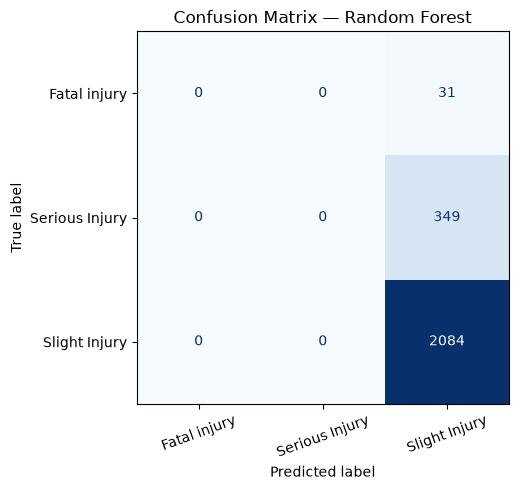

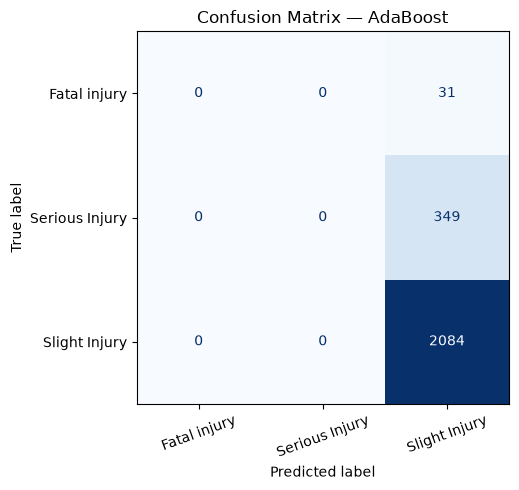

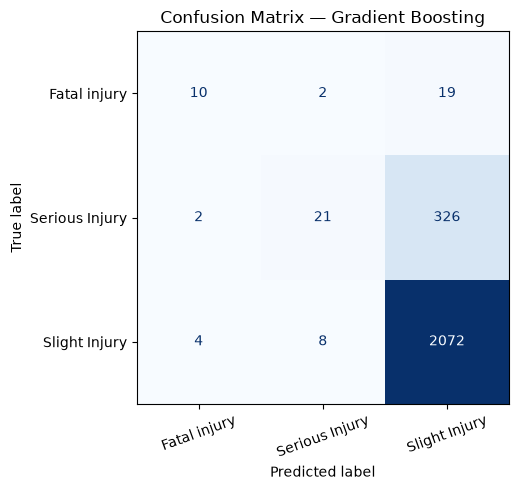

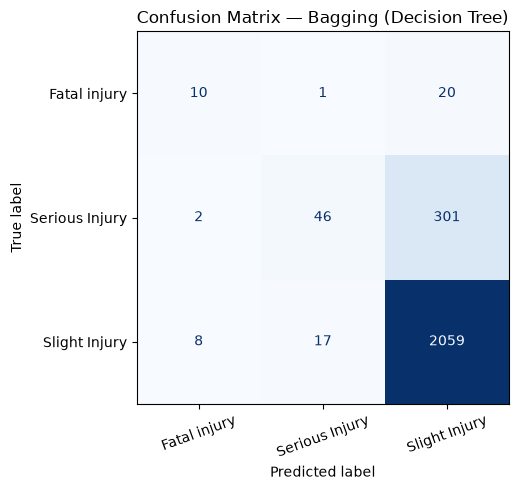

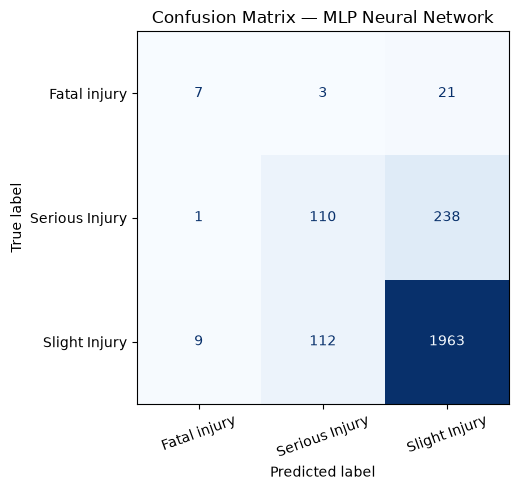

In [63]:
for model_name, predictions in part_b_predictions.items():
    cm = confusion_matrix(
        y_test,
        predictions,
        labels=part_b_fitted_models[model_name].classes_
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=part_b_fitted_models[model_name].classes_
    )

    fig, ax = plt.subplots(figsize=(7, 5))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {model_name}")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()


## 18. Part B Model Comparison

A bar chart compares the weighted F1-score of the five Part B
models.

Weighted F1-score combines precision and recall while accounting
for class support. It provides a useful comparison measure when
the target classes have unequal frequencies.

The chart is used to identify promising candidates, but the final
decision should also consider accuracy, class-wise performance,
ROC-AUC, and the project's objective.


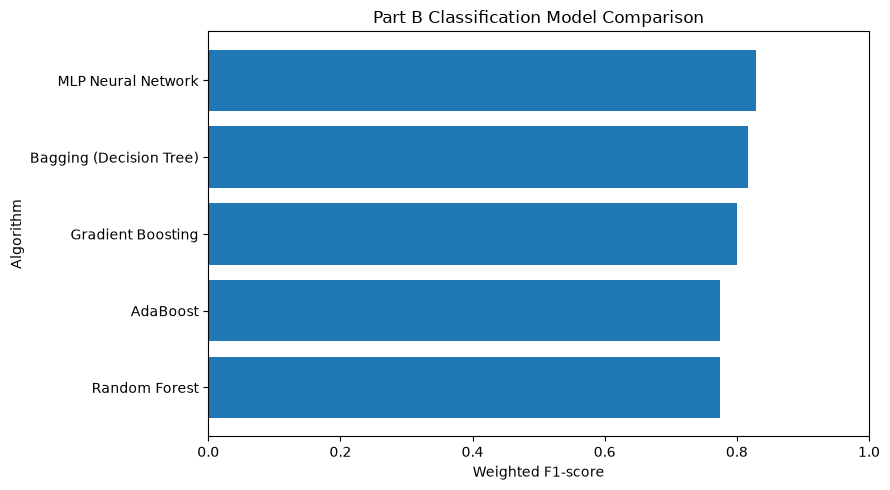

In [64]:
plot_df = part_b_results_df.sort_values("F1_Weighted", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_df["Algorithm"], plot_df["F1_Weighted"])

plt.xlabel("Weighted F1-score")
plt.ylabel("Algorithm")
plt.title("Part B Classification Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


## 19. Hyperparameter Tuning — Random Forest

Hyperparameters are configuration values selected before model
training. They control how an algorithm learns from the data.

For Random Forest, important hyperparameters include the number
of trees, maximum tree depth, minimum samples required for a split,
minimum samples per leaf, and class-weighting strategy.

RandomizedSearchCV evaluates a sample of parameter combinations
using stratified cross-validation on the training data.

Weighted F1-score is used as the tuning objective because the
target classes are imbalanced. The held-out test set is not used
to select hyperparameters.

After tuning, the best estimator is evaluated on the same test set
as the baseline Random Forest, allowing a fair comparison.


In [65]:
random_forest_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    param_distributions={
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 10, 20, 30],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", "log2"],
        "class_weight": ["balanced", "balanced_subsample"]
    },
    n_iter=8,
    scoring="f1_weighted",
    cv=StratifiedKFold(
        n_splits=3,
        shuffle=True,
        random_state=RANDOM_STATE
    ),
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

random_forest_search.fit(X_train_processed, y_train)

tuned_random_forest = random_forest_search.best_estimator_
tuned_rf_predictions = tuned_random_forest.predict(X_test_processed)

print("Best parameters:")
print(random_forest_search.best_params_)

print("\nBest cross-validation weighted F1:")
print(round(random_forest_search.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 30, 'class_weight': 'balanced'}

Best cross-validation weighted F1:
0.7855



## 20. Baseline Versus Tuned Random Forest

The baseline Random Forest uses the original hyperparameter
configuration. The tuned Random Forest uses the best parameter
combination found by cross-validation.

Both models are evaluated on the same held-out test set. Their
weighted F1-scores are compared to document whether tuning improved
performance.

A higher cross-validation score does not guarantee a higher test
score. If the test score decreases, this result should be reported
honestly rather than described as an improvement.


In [66]:
baseline_rf = part_b_fitted_models["Random Forest"]

baseline_rf_predictions = baseline_rf.predict(X_test_processed)

baseline_rf_f1 = f1_score(
    y_test, baseline_rf_predictions,
    average="weighted", zero_division=0
)

tuned_rf_f1 = f1_score(
    y_test, tuned_rf_predictions,
    average="weighted", zero_division=0
)

tuning_comparison = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Tuned Random Forest"],
    "Test Weighted F1": [baseline_rf_f1, tuned_rf_f1]
})

display(tuning_comparison.round(4))

print("Weighted F1 change:", round(tuned_rf_f1 - baseline_rf_f1, 4))

,Model,Test Weighted F1
0,Baseline Random Forest,0.7751
1,Tuned Random Forest,0.7940


Weighted F1 change: 0.0188


In [67]:
part_b_fitted_models["Random Forest"] = tuned_random_forest
part_b_predictions["Random Forest"] = tuned_rf_predictions


### 21 Loading Part A Models

The trained Part A classifiers are loaded from the saved model file.
They will be combined with the five Part B classifiers to create
the consolidated comparison table required by the capstone rubric.

The Part A models must use compatible feature preprocessing and
the same test records as Part B for a valid comparison.


In [68]:

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

part_a_bundle = joblib.load("../models/part_a_bundle.joblib")

part_a_fitted_models = part_a_bundle["models"]
preprocessor = part_a_bundle["preprocessor"]

X_train_processed = part_a_bundle["X_train_processed"]
X_test_processed = part_a_bundle["X_test_processed"]

y_train = part_a_bundle["y_train"]
y_test = part_a_bundle["y_test"]

RANDOM_STATE = part_a_bundle["random_state"]

print("Shared Part A data loaded successfully.")
print("Part A models:", list(part_a_fitted_models.keys()))
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Training labels:", len(y_train))
print("Testing labels:", len(y_test))


Shared Part A data loaded successfully.
Part A models: ['Logistic Regression', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Decision Tree', 'Support Vector Machine']
Training shape: (9852, 203)
Testing shape: (2464, 203)
Training labels: 9852
Testing labels: 2464


In [69]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Import K-Nearest Neighbors
from sklearn.neighbors import KNeighborsClassifier

# Import Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

# Import Decision Tree
from sklearn.tree import DecisionTreeClassifier

# Import Support Vector Machine classifier
from sklearn.svm import SVC

# Display confirmation
print("Five Classification Part-A algorithms imported successfully.")

Five Classification Part-A algorithms imported successfully.



## Training Part B Models on the Shared Dataset

The five Part B algorithms are trained on the same processed training
data used by the Part A algorithms.

This ensures consistency in the input features, target labels,
preprocessing, and held-out test data.

The MLP classifier uses early_stopping=False to avoid the validation
score error encountered during the earlier training attempt.


In [70]:

part_b_fitted_models = {}
part_b_predictions = {}

for model_name, model in part_b_models.items():
    print(f"\nTraining {model_name}...")

    if model_name == "MLP Neural Network":
        model.set_params(early_stopping=False)

    model.fit(X_train_processed, y_train)

    part_b_fitted_models[model_name] = model
    part_b_predictions[model_name] = model.predict(X_test_processed)

    print(f"{model_name} trained successfully.")

print("\nAll five Part B models trained on the shared split.")



Training Random Forest...
Random Forest trained successfully.

Training AdaBoost...
AdaBoost trained successfully.

Training Gradient Boosting...
Gradient Boosting trained successfully.

Training Bagging (Decision Tree)...
Bagging (Decision Tree) trained successfully.

Training MLP Neural Network...
MLP Neural Network trained successfully.

All five Part B models trained on the shared split.



## Consolidated Classification Results — All Ten Models

The five Part A classifiers and five Part B classifiers are combined
in one comparison table.

All models are evaluated using the same held-out test data. The
evaluation metrics are accuracy, weighted precision, weighted recall,
weighted F1-score, and multiclass ROC-AUC using the One-vs-Rest
approach where the required prediction scores are available.

The table is sorted by weighted F1-score to make model comparison
easier. The best model should also be checked using its confusion
matrix and class-wise classification report, especially for the
minority fatal-injury class.


In [71]:

def calculate_metrics(model, X_eval, y_true, y_pred):
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Weighted": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall_Weighted": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "ROC_AUC_OVR": np.nan
    }

    try:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(X_eval)
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(X_eval)
        else:
            y_score = None

        if y_score is not None:
            results["ROC_AUC_OVR"] = roc_auc_score(
                y_true,
                y_score,
                labels=model.classes_,
                multi_class="ovr",
                average="weighted"
            )
    except (ValueError, AttributeError):
        # Leave ROC-AUC as NaN if it cannot be calculated
        pass

    return results


all_classification_models = {
    **part_a_fitted_models,
    **part_b_fitted_models
}

all_results = []

for model_name, model in all_classification_models.items():
    predictions = model.predict(X_test_processed)

    metrics = calculate_metrics(
        model,
        X_test_processed,
        y_test,
        predictions
    )

    metrics["Algorithm"] = model_name
    all_results.append(metrics)

final_classification_results = pd.DataFrame(all_results)

final_classification_results = (
    final_classification_results[
        [
            "Algorithm",
            "Accuracy",
            "Precision_Weighted",
            "Recall_Weighted",
            "F1_Weighted",
            "ROC_AUC_OVR"
        ]
    ]
    .sort_values("F1_Weighted", ascending=False)
    .reset_index(drop=True)
)

display(final_classification_results.round(4))

print("Total models compared:", len(final_classification_results))


,Algorithm,Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,ROC_AUC_OVR
0,Bagging (Decision Tree),0.8523,0.8360,0.8523,0.7957,0.7264
1,K-Nearest Neighbors,0.8385,0.7784,0.8385,0.7893,0.6181
2,Gradient Boosting,0.8470,0.8054,0.8470,0.7868,0.6501
3,Random Forest,0.8466,0.8576,0.8466,0.7771,0.6858
4,AdaBoost,0.8458,0.7153,0.8458,0.7751,0.6145
5,MLP Neural Network,0.7776,0.7621,0.7776,0.7695,0.6034
6,Decision Tree,0.7593,0.7676,0.7593,0.7633,0.5611
7,Support Vector Machine,0.6924,0.7850,0.6924,0.7267,0.6428
8,Logistic Regression,0.5065,0.7611,0.5065,0.5902,0.5689
9,Gaussian Naive Bayes,0.0913,0.7712,0.0913,0.1241,0.5062


Total models compared: 10



## 22. Five-Fold Cross-Validation

A single train-test split provides one estimate of model performance.
Cross-validation provides additional evidence by evaluating a model
across multiple training and validation folds.

In five-fold stratified cross-validation, the training data is
divided into five folds while attempting to preserve class
proportions. The model is trained on four folds and validated on
the remaining fold. This process is repeated until every fold has
served as the validation set.

The mean and standard deviation of weighted F1-score are reported
for the selected candidates. Cross-validation is conducted on the
training data, not the held-out test set.

For the strongest evaluation practice, choose the top candidates
using training-set cross-validation, then use the test set only
for the final unbiased comparison.


In [72]:
top_two_names = (
    final_classification_results
    .head(2)["Algorithm"]
    .tolist()
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_results = []

for model_name in top_two_names:
    model = all_classification_models[model_name]

    scores = cross_val_score(
        clone(model),
        X_train_processed,
        y_train,
        cv=cv,
        scoring="f1_weighted",
        n_jobs=-1
    )

    cv_results.append({
        "Algorithm": model_name,
        "Mean CV Weighted F1": scores.mean(),
        "Standard Deviation": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df.round(4))

,Algorithm,Mean CV Weighted F1,Standard Deviation
0,Bagging (Decision Tree),0.7978,0.0031
1,K-Nearest Neighbors,0.7973,0.0052



## 23. Final Model Selection

The consolidated comparison table is used to identify the leading
classification candidate.

Weighted F1-score is used as the initial ranking criterion.
The final decision must also consider class-wise precision and
recall, confusion matrices, ROC-AUC where available, and the
five-fold cross-validation results.

Because accident severity prediction is a multiclass problem,
performance on the minority fatal-injury class must not be ignored
in favor of high overall accuracy.

The selected model and its results will be reported using the
actual measured values from this experiment.


Top model by test weighted F1: Bagging (Decision Tree)

Final classification report:
                precision    recall  f1-score   support

  Fatal injury       0.50      0.06      0.11        31
Serious Injury       0.76      0.06      0.12       349
 Slight Injury       0.85      1.00      0.92      2084

      accuracy                           0.85      2464
     macro avg       0.70      0.37      0.38      2464
  weighted avg       0.84      0.85      0.80      2464



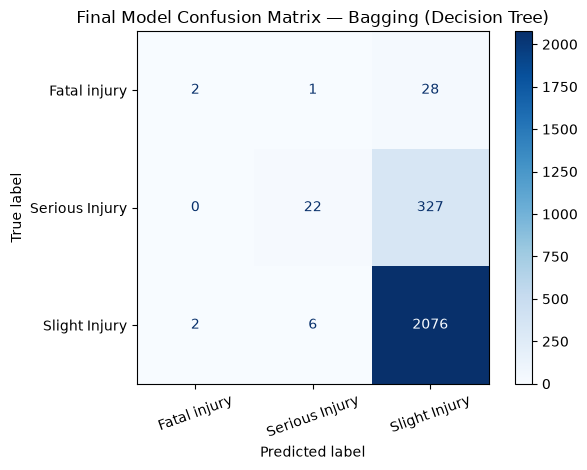

In [73]:
best_model_name = final_classification_results.iloc[0]["Algorithm"]
best_model = all_classification_models[best_model_name]

print("Top model by test weighted F1:", best_model_name)

best_predictions = best_model.predict(X_test_processed)

print("\nFinal classification report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=best_model.classes_,
    display_labels=best_model.classes_,
    xticks_rotation=20,
    cmap="Blues"
)

plt.title(f"Final Model Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()


## Final Comparison of Ten Classification Algorithms

This visualization compares the accuracy, weighted precision,
weighted recall, and weighted F1-score of all ten classification
algorithms.

Using the same scale makes it easier to identify differences in
performance. Weighted F1-score is particularly useful when the
target classes have unequal frequencies, although class-wise
performance must also be examined.

The graph supports the consolidated results table and helps
identify promising models for further evaluation.


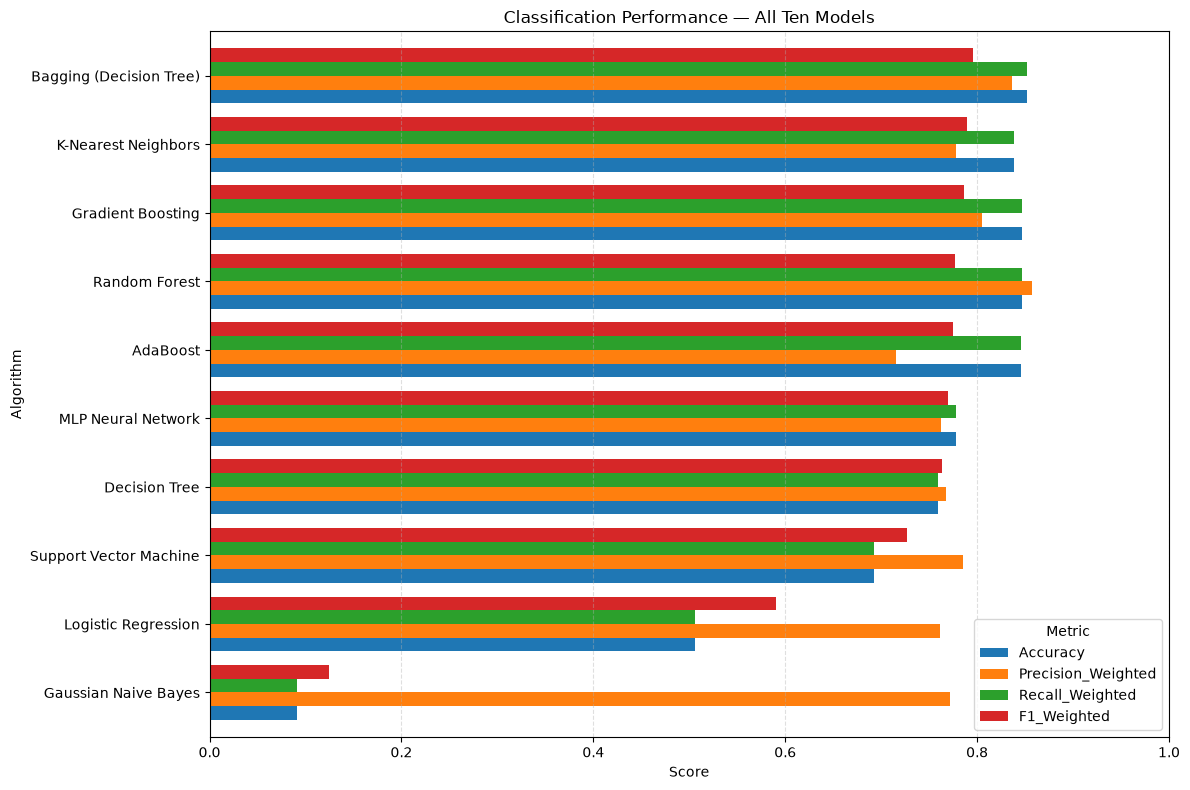

In [74]:
import matplotlib.pyplot as plt
import numpy as np

metrics_to_plot = [
    "Accuracy",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted"
]

plot_df = final_classification_results.copy()

ax = (
    plot_df.set_index("Algorithm")[metrics_to_plot]
    .sort_values("F1_Weighted")
    .plot(kind="barh", figsize=(12, 8), width=0.8)
)

ax.set_title("Classification Performance — All Ten Models")
ax.set_xlabel("Score")
ax.set_ylabel("Algorithm")
ax.set_xlim(0, 1)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.legend(title="Metric", loc="lower right")

plt.tight_layout()
plt.show()


## Normalized Confusion Matrix of the Selected Model

A normalized confusion matrix presents the classification results
as proportions rather than raw counts.

Each row corresponds to an actual severity class. The diagonal
represents correctly classified records, while off-diagonal cells
show misclassifications.

Row normalization makes class-level performance easier to compare
even when the severity categories contain different numbers of
records.


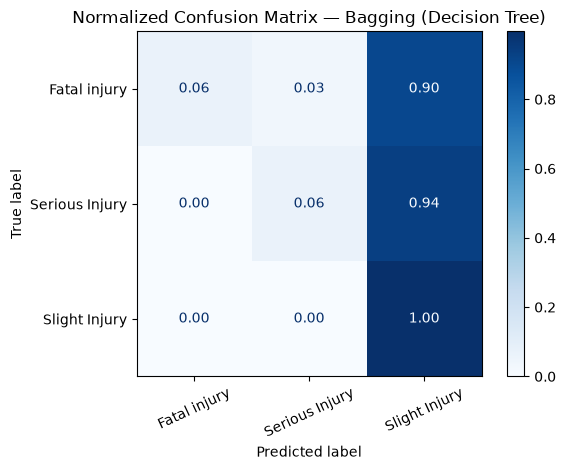

Selected model: Bagging (Decision Tree)


In [75]:
from sklearn.metrics import ConfusionMatrixDisplay

# Use the selected model from your final comparison
best_model_name = final_classification_results.iloc[0]["Algorithm"]
best_model = all_classification_models[best_model_name]

best_predictions = best_model.predict(X_test_processed)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=best_model.classes_,
    display_labels=best_model.classes_,
    normalize="true",
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=25
)

plt.title(f"Normalized Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print("Selected model:", best_model_name)


## Multiclass ROC Curve — One-vs-Rest

The Receiver Operating Characteristic (ROC) curve plots the
true-positive rate against the false-positive rate at different
classification thresholds.

For multiclass accident severity prediction, the One-vs-Rest
approach evaluates each severity category against all the
remaining categories.

The Area Under the Curve (AUC) summarizes discrimination
performance: a larger AUC generally indicates better separation
of the relevant class from the others.

ROC curves should be interpreted alongside class-wise recall
and the confusion matrix, especially for the minority class.


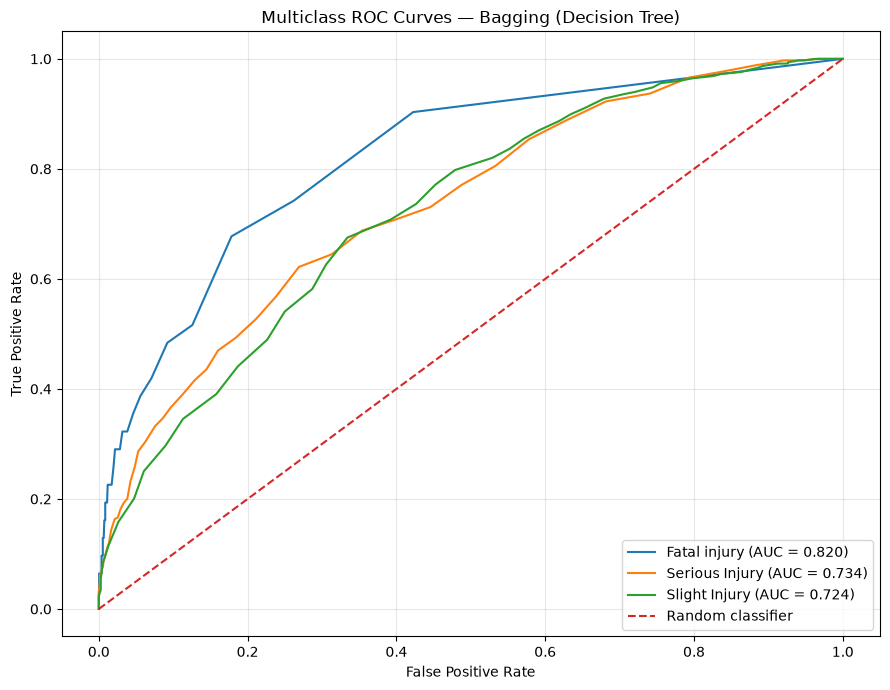

In [76]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

classes = np.asarray(best_model.classes_)
y_test_binary = label_binarize(y_test, classes=classes)

if not hasattr(best_model, "predict_proba"):
    print("ROC curves require predict_proba for this code.")
else:
    y_scores = best_model.predict_proba(X_test_processed)

    plt.figure(figsize=(9, 7))

    for i, class_name in enumerate(classes):
        if len(np.unique(y_test_binary[:, i])) < 2:
            print(f"Skipping ROC for {class_name}: only one label value.")
            continue

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            y_scores[:, i]
        )

        class_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC = {class_auc:.3f})"
        )

    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Multiclass ROC Curves — {best_model_name}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## Class-Wise Performance Analysis

Overall weighted metrics can hide weaknesses in minority classes.
This visualization compares precision, recall, and F1-score for
each accident severity category.

Recall indicates the proportion of actual cases in a class that
the model identifies correctly. In this application, the Fatal
injury class deserves particular attention because missed cases
may be important from a safety-analysis perspective.

This graph complements the confusion matrix and classification
report.


,Class,Precision,Recall,F1-score,Support
0,Fatal injury,0.5000,0.0645,0.1143,31
1,Serious Injury,0.7586,0.0630,0.1164,349
2,Slight Injury,0.8540,0.9962,0.9196,2084


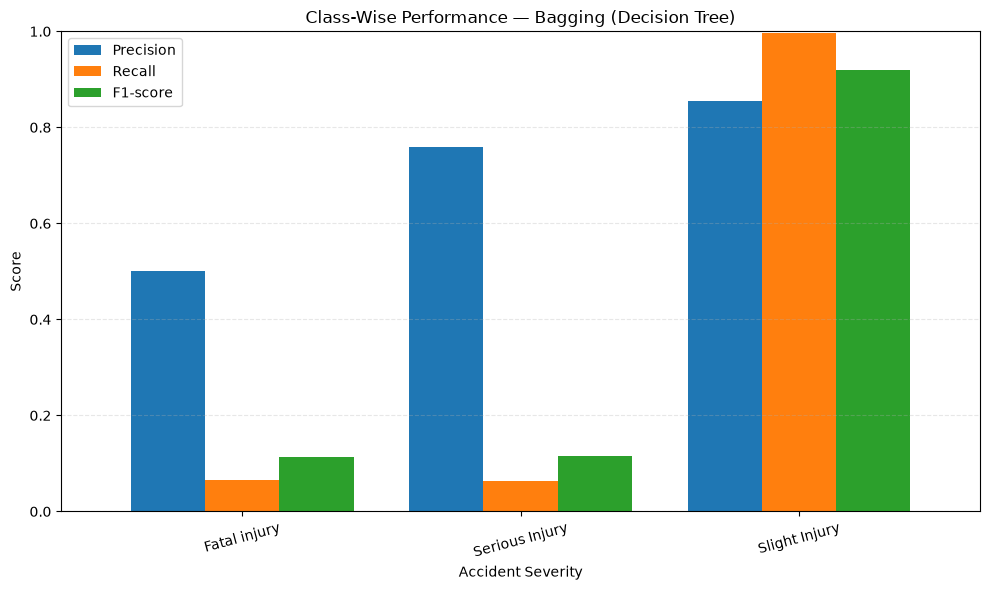

In [77]:
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_test,
    best_predictions,
    labels=best_model.classes_,
    zero_division=0
)

class_metrics = pd.DataFrame({
    "Class": best_model.classes_,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

display(class_metrics.round(4))

class_metrics.set_index("Class")[["Precision", "Recall", "F1-score"]].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title(f"Class-Wise Performance — {best_model_name}")
plt.ylabel("Score")
plt.xlabel("Accident Severity")
plt.xticks(rotation=15)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend(loc="best")
plt.tight_layout()
plt.show()


## Hyperparameter Tuning: Baseline vs Tuned Random Forest

The baseline and tuned Random Forest models are evaluated on the
same test set using weighted F1-score.

This comparison shows whether the selected hyperparameters improved
the measured test performance. Hyperparameter selection itself is
performed using cross-validation on the training data.

If the tuned model performs worse, this should be reported honestly
and investigated rather than described as an improvement.


,Model,Weighted F1
0,Baseline Random Forest,0.7751
1,Tuned Random Forest,0.7940


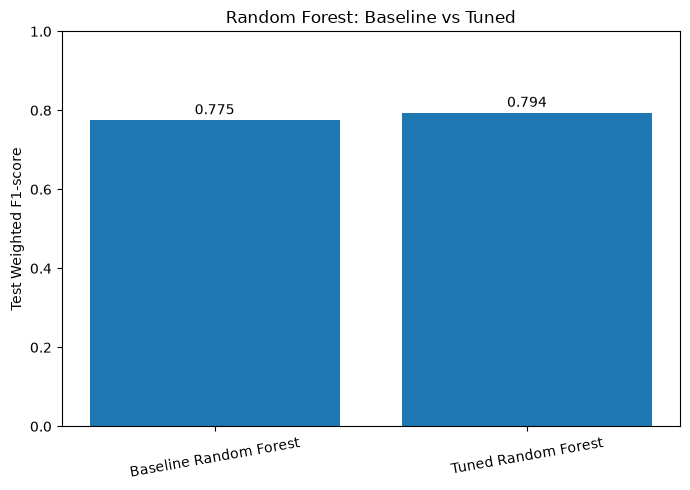

Change in weighted F1: +0.0188


In [78]:
baseline_f1 = f1_score(
    y_test,
    baseline_rf_predictions,
    average="weighted",
    zero_division=0
)

tuned_f1 = f1_score(
    y_test,
    tuned_rf_predictions,
    average="weighted",
    zero_division=0
)

tuning_df = pd.DataFrame({
    "Model": ["Baseline Random Forest", "Tuned Random Forest"],
    "Weighted F1": [baseline_f1, tuned_f1]
})

display(tuning_df.round(4))

plt.figure(figsize=(7, 5))
bars = plt.bar(tuning_df["Model"], tuning_df["Weighted F1"])

plt.ylim(0, 1)
plt.ylabel("Test Weighted F1-score")
plt.title("Random Forest: Baseline vs Tuned")
plt.xticks(rotation=10)

for bar, value in zip(bars, tuning_df["Weighted F1"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

print(f"Change in weighted F1: {tuned_f1 - baseline_f1:+.4f}")


## Saving Part B Models

The five trained Part B classifiers are saved to the models
directory so they can be reused without retraining.

The saved models include Random Forest, AdaBoost, Gradient Boosting,
Bagging with a Decision Tree, and the MLP Neural Network.

The tuned Random Forest is saved if the model dictionary has
already been updated with the tuned estimator.


In [79]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    part_b_fitted_models,
    "../models/part_b_classification_models.joblib"
)

print("Part B models saved successfully!")
print("Saved models:", list(part_b_fitted_models.keys()))
print("File: ../models/part_b_classification_models.joblib")

Part B models saved successfully!
Saved models: ['Random Forest', 'AdaBoost', 'Gradient Boosting', 'Bagging (Decision Tree)', 'MLP Neural Network']
File: ../models/part_b_classification_models.joblib



## Final Conclusion

This project evaluated ten machine learning algorithms for road
traffic accident severity classification. Five algorithms were
evaluated in Classification Part A, and five additional algorithms
were evaluated in Classification Part B.

The models were compared using accuracy, weighted precision,
weighted recall, weighted F1-score, and multiclass ROC-AUC where
available. Confusion matrices and class-wise classification reports
were used to examine the strengths and weaknesses of the models.

The final model selection considers both overall predictive
performance and the ability to recognize the different accident
severity categories. Particular attention is given to the Fatal
injury class because overall metrics may hide poor minority-class
performance.

Random Forest hyperparameter tuning was evaluated using a held-out
test set after selecting parameters through cross-validation.
The measured baseline and tuned scores are reported to establish
whether tuning improved the test results.

These experiments provide a comparative assessment of the selected
classification algorithms. The results describe patterns in the
available dataset and should not be interpreted as proof of causal
relationships or as a replacement for professional road-safety
assessment.
